# Can planning with the wrong beliefs look like habit?

**A computational replication of Feher da Silva & Hare (2020), *Humans primarily use model-based inference in the two-stage task*.** The authors ask whether the standard two-stage task can distinguish a person who reinforces a rewarded action from a person who plans with an inaccurate model of the game. Their evidence comes from simulated agents with known strategies and from choices people actually made under three versions of the task. [Published paper](https://doi.org/10.1038/s41562-020-0905-y) · [Open preprint](https://www.biorxiv.org/content/10.1101/682922v3.full) · [Authors’ code](https://github.com/carolfs/muddled_models)

The direct replication targets are the published Figure 2 simulated planning weights and the stronger human reward-by-transition interaction and larger hybrid weights under the Spaceship and Magic carpet instructions. We add a finite-trial recovery experiment, compare five learning models with BIC, and check the selected models against new histories drawn from their parameter posteriors. The last section quantifies agreement and disagreement.

**Running the notebook.** Run all cells from the repository root with the packages in `requirements.txt`. The source trials, results, and embedded figures are included. The heavy stages reuse a result only when its settings, source files, input data, and output digests match. Set `REFIT = True` to rerun the optimizers, simulations, and posterior sampler. Each random experiment has its own fixed seed.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from replication import analysis as a
from replication import plots
from scipy.optimize import minimize
from replication.models import BOUNDS, PARAMS, nll
from replication.study import DATA, DESIGN, OUT, SEED, run_stage

REFIT = False
JOBS = min(8, os.cpu_count() or 1)
settings = {name: values.copy() for name, values in DESIGN.items()}
plots.set_style()
OUT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 15)

def figure(fig, filename):
    path = OUT / filename
    fig.savefig(path, facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

def result_table(frame, filename):
    frame.to_csv(OUT / filename, index=False, lineterminator="\n")
    display(frame.round(3))

display(pd.DataFrame(settings).T.fillna("—"))

,seed,starts,n_agents,n_refit,n_trials,n_rep,n_particles,min_ess,max_particles
human,1182021.0,10.0,—,—,—,—,—,—,—
figure2,1182022.0,10.0,1000.0,1000.0,1000.0,—,—,—,—
recovery,1182023.0,10.0,100.0,—,250.0,—,—,—,—
predictive,1182024.0,—,—,—,—,500.0,2048.0,200.0,65536.0


## 1 · Understand the task and its competing models

On each trial a participant picks a first action, travels to a second state, selects one of two options there, and sees a binary reward. Each first action reaches its usual state with probability 0.70 and the other state with probability 0.30. Four changing reward probabilities make yesterday’s best second-stage option worth reconsidering. The standard model-free (MF) learner updates a stored value for a first action. A model-based (MB) learner uses the transition probabilities and estimated second-stage values to plan.

Suppose carpet A usually goes to the pink mountain and B usually goes to blue. You take A, land at blue via the rare route, and a genie gives you a coin. Reinforcing A makes repeating it more likely. Planning can instead make B more attractive because B is the reliable route back to blue. A reward on a **common** transition makes both strategies more likely to repeat the first action. The two explanations diverge most clearly after a **rare** transition. [Authors’ task instructions](https://github.com/carolfs/muddled_models/blob/master/magic_carpet/assets/game_instructions.txt)

| Family | Rule for the first choice | Free parameters |
|---|---|---|
| MF | Uses the learned value of a first action in the current first-stage configuration. | $\alpha_1,\alpha_2,\lambda,\beta_1,\beta_2,p$ |
| MB | Weights the best current value in each destination by its 70/30 transition probabilities. | $\alpha_2,\beta_1,\beta_2,p$ |
| Hybrid | Combines MB and MF values in proportions $w$ and $1-w$. | All MF parameters and $w$ |
| Unlucky symbol | Plans with correct transitions but discounts the expected payout after choosing first action 0 by a factor $\eta$. This factor also scales the second-stage choice values on that route. | $\alpha_2,\beta_1,\beta_2,p,\eta$ |
| Transition-dependent learning rates (TDLR) | Plans using the usual transitions, but learns at different rates from outcomes reached via common and rare routes. | $\alpha_\mathrm{common},\alpha_\mathrm{rare},\beta_1,\beta_2,p$ |

| Parameter | What changing it does |
|---|---|
| $\alpha_1$ | Larger values update the chosen first-stage MF value more strongly on each trial. |
| $\alpha_2$ | Larger values make the chosen second-stage value more sensitive to the latest reward prediction error. |
| $\lambda$ | Controls how much of the final reward prediction error immediately reaches the first action. At 0 the update uses only the previously estimated second-stage value. At 1 the first action updates directly toward the observed reward. |
| $\beta_1,\beta_2$ | Inverse temperatures for the first and second choices. Higher values make choices follow small differences in value more consistently. |
| $p$ | First-choice repetition bias in value units. Positive values favor the previous relative first action, negative values favor switching, and $\beta_1$ scales its influence. |
| $w$ | Relative contribution of planned value at the first choice. Zero gives MF and one gives MB. A fitted weight describes this model’s valuation rule. |
| $\eta$ | Fraction of the expected value retained after the “unlucky” choice. At 1 the belief disappears. |
| $\alpha_\mathrm{common},\alpha_\mathrm{rare}$ | Separate rates for updating second-stage value after common and rare transitions. Equal rates give the MB rule. |

With $V(s,a)$ the second-stage value, $M_j=\max_a V(j,a)$, and first actions numbered by their usual destination, the MB difference between action 1 and action 0 is $0.4(M_1-M_0)$. If $\Delta Q$ is the corresponding difference between stored MF values and $h$ is $+1$ after action 1, $-1$ after action 0, and 0 on the first trial, the hybrid first-choice log odds are
$$\beta_1\,[w\,0.4(M_1-M_0)+(1-w)\Delta Q+p h].$$
At the second stage the standard log odds are $\beta_2[V(s,1)-V(s,0)]$. Starting from zeros, the chosen entries update using their **pre-update** values:
$$Q(s_1,a_1)\leftarrow Q(s_1,a_1)+\alpha_1[V(s_2,a_2)-Q(s_1,a_1)+\lambda(r-V(s_2,a_2))],\qquad
V(s_2,a_2)\leftarrow V(s_2,a_2)+\alpha_2[r-V(s_2,a_2)].$$
MF and hybrid keep separate first-stage values for each of the four Spaceship announcements. The simulation and likelihood replay implement the same ordering of choice, transition, feedback, and learning. [Original hybrid model](https://github.com/carolfs/muddled_models/blob/master/analyses_simulations/models/hybrid.stan) · [Published agent algorithms](https://github.com/carolfs/muddled_models/blob/master/analyses_simulations/wrong_model_based_agents.py)

### Published data and exclusions

The standard-instruction data are an existing sample from Kool et al. The other two samples performed the authors’ Spaceship or Magic carpet task with detailed causal explanations. They are separate cohorts. The comparison combines changes in instructions, task presentation, and sampling. In Spaceship we code a first action by its intended planet. Repeating the same intended destination can require pressing a different button under a different flight announcement. [Kool et al. data](https://github.com/wkool/tradeoffs/tree/master/data/daw%20paradigm) · [Data dictionary, pinned inputs and rebuild instructions](data/README.md)

The counts below exclude practice. All participants with published main-task choices enter the analysis. An omitted first or second response removes the trial from both the learning updates and the choice likelihood. The four scheduled reward probabilities remain available for each attempt.

In [2]:
trials = a.load_trials(DATA)
audit = a.participant_audit(trials)
display(audit)
complete = trials.loc[trials.valid.eq(1)]
assert audit.participants.sum() == 251 and len(complete) == 34_824
assert complete[["p00", "p01", "p10", "p11"]].notna().all().all()

,participants,main_trials,completed,omissions
cohort,,,,
Common instructions,206,25750,24750,1000
Spaceship,21,5273,5250,23
Magic carpet,24,4934,4824,110


## 2 · Simulate the behavioral signature

For the three Figure 2 generators, use the paper’s 1,000 trials per agent, 1,000 agents per type, and its fixed learning rates and choice temperatures. Rewards follow four independent Gaussian walks, initialized uniformly from 0.25 to 0.75 and reflected at those boundaries, with step SD 0.025. The first screen has one configuration. The MF and hybrid panels add forward simulations for comparison. The paper used idealized bars as its reference panels. The settings below specify each of our generators. [Simulation settings](https://github.com/carolfs/muddled_models/blob/master/analyses_simulations/wrong_model_based_agents.py)

For each agent calculate the probability of repeating the **first** action on the next trial in four cells, defined by the previous reward and transition. A simple reward effect raises both lines after a reward. Planning predicts that the common-transition line rises while the rare-transition line falls. The simulated hybrid and the two mistaken planners show why the same plot can admit different explanations. Error bars are 95% bootstrap intervals for the mean across agents.

,alpha1,alpha2,lam,beta1,beta2,p,w,eta,alpha_common,alpha_rare
MF,0.5,0.5,0.7,5.0,5.0,0.0,—,—,—,—
MB,—,0.5,—,5.0,5.0,0.0,—,—,—,—
Hybrid,0.5,0.5,0.7,5.0,5.0,0.0,0.5,—,—,—
Unlucky,—,0.5,—,5.0,5.0,0.0,—,0.5,—,—
TDLR,—,—,—,5.0,5.0,0.0,—,—,0.8,0.2


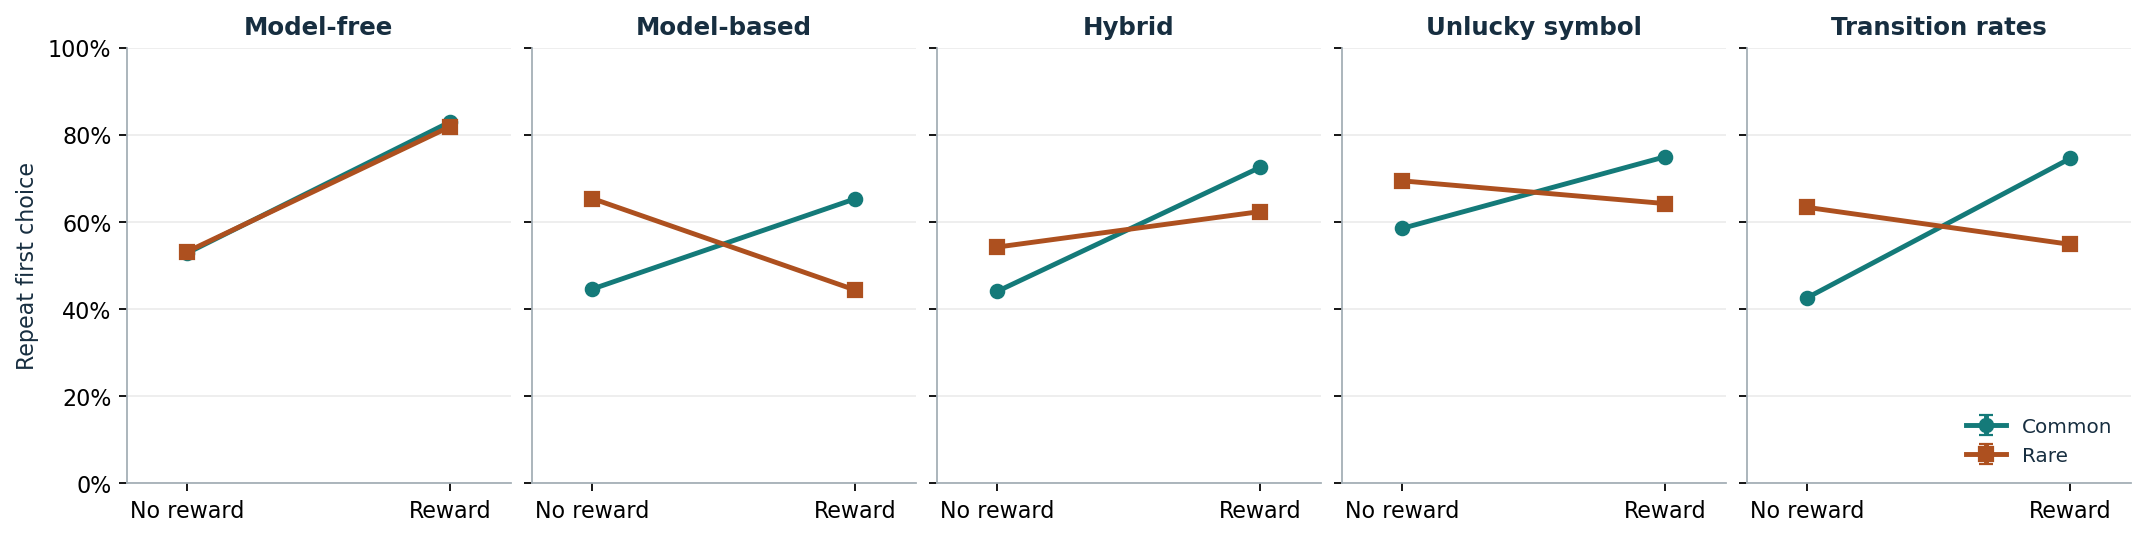

In [3]:
display(pd.DataFrame.from_dict(a.FIG2_PARAMETERS, orient="index").reindex(a.FAMILIES).fillna("—"))
agents, = run_stage("figure2", settings=settings["figure2"], jobs=JOBS, refresh=REFIT)
figure(plots.signature_plot(agents, "generator", a.FAMILIES, SEED), "simulated_stay.png")

### The same plot for the human participants

Each participant contributes equally to their cohort’s mean. We pair successive **completed** trials, as in the original analysis. The interval resamples participants with replacement. The paper estimated stay rates with a hierarchical logistic regression. These directly counted probabilities give a check that can be read independently of a model fit. [Published stay analysis](https://github.com/carolfs/muddled_models/blob/master/analyses_simulations/stay_probabilities_human_data.py)

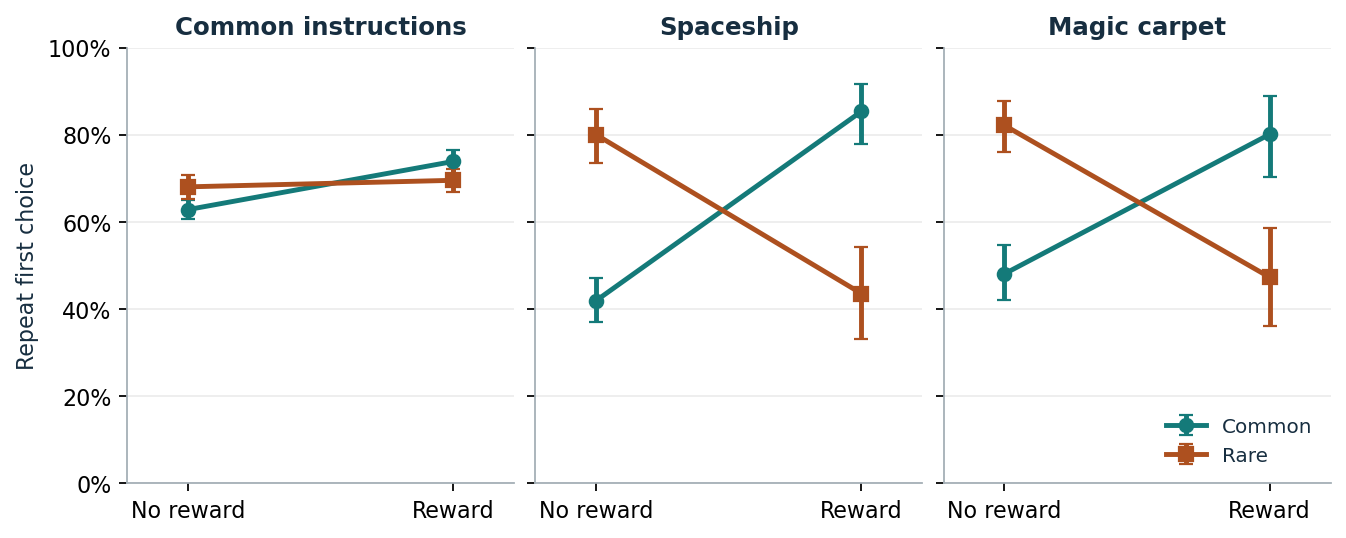

In [4]:
human_stay = a.human_signatures(trials)
strict_stay = a.human_signatures(trials, adjacent_only=True)
figure(plots.signature_plot(human_stay, "cohort", a.COHORTS, SEED+8), "human_stay.png")

On the paper’s ±1 predictor coding, the reward coefficient averages the reward effect across transition types. The interaction is one quarter of the difference between the two reward effects in log odds. We calculate each person's saturated four-cell logistic coefficients, adding half a count to stays and switches to keep the log odds finite, then bootstrap people. This gives a descriptive approximation to the paper’s hierarchical coefficients. The last estimate uses only adjacent original trial numbers, so a missed response interrupts a pair. [Source regression](https://github.com/carolfs/muddled_models/blob/master/analyses_simulations/logistic_regression_human_data.py)

In [5]:
contrasts = a.contrast_table(human_stay, strict_stay, SEED+10)
result_table(contrasts, "human_stay_contrasts.csv")

,cohort,effect,estimate,lower,upper,adjacent_only,people
0,Common instructions,reward_coef,0.233,0.183,0.285,0.240,206
1,Common instructions,interaction_coef,0.190,0.133,0.248,0.189,206
2,Spaceship,reward_coef,0.132,0.006,0.259,0.135,21
3,Spaceship,interaction_coef,1.162,0.891,1.427,1.162,21
4,Magic carpet,reward_coef,0.079,-0.043,0.205,0.077,24
5,Magic carpet,interaction_coef,1.076,0.728,1.440,1.077,24


## 3 · Recover known parameters and learning rules

**The authors’ Figure 2 experiment.** Give the hybrid fitter the choices from the three purely planning generators and estimate $w$ blind to their identities. For the correct MB agent the ground truth is $w=1$. For the two mistaken planners, the fitted weight quantifies what happens when the generating model is missing from the analysis.

We follow the public code’s ten optimization starts. Its Stan program includes half-Cauchy priors with scale 5 on both positive inverse temperatures and a Cauchy prior with scale 1 on perseveration. We include those terms for this figure. The paper calls the procedure maximum likelihood, while the public objective includes these penalties. The percentile intervals in the table describe variation across synthetic agents. Open markers in the plot show the published medians. [Published Figure 2](https://www.nature.com/articles/s41562-020-0905-y/figures/2) · [Stan objective](https://github.com/carolfs/muddled_models/blob/master/analyses_simulations/models/hybrid_no_log_lik.stan)

,generator,n,reproduced_median,replicate_2.5%,replicate_97.5%,published_median,difference,published_2.5%,published_97.5%
0,MB,1000,0.943,0.670,1.000,0.94,0.003,0.74,1.00
1,Unlucky,1000,0.355,0.220,0.473,0.36,-0.005,0.24,0.48
2,TDLR,1000,0.804,0.702,0.889,0.80,0.004,0.70,0.90


The correct planner's lower 2.5th percentile is **0.67**, compared with **0.74** in the paper. Agreement is closer at the medians than in this tail.

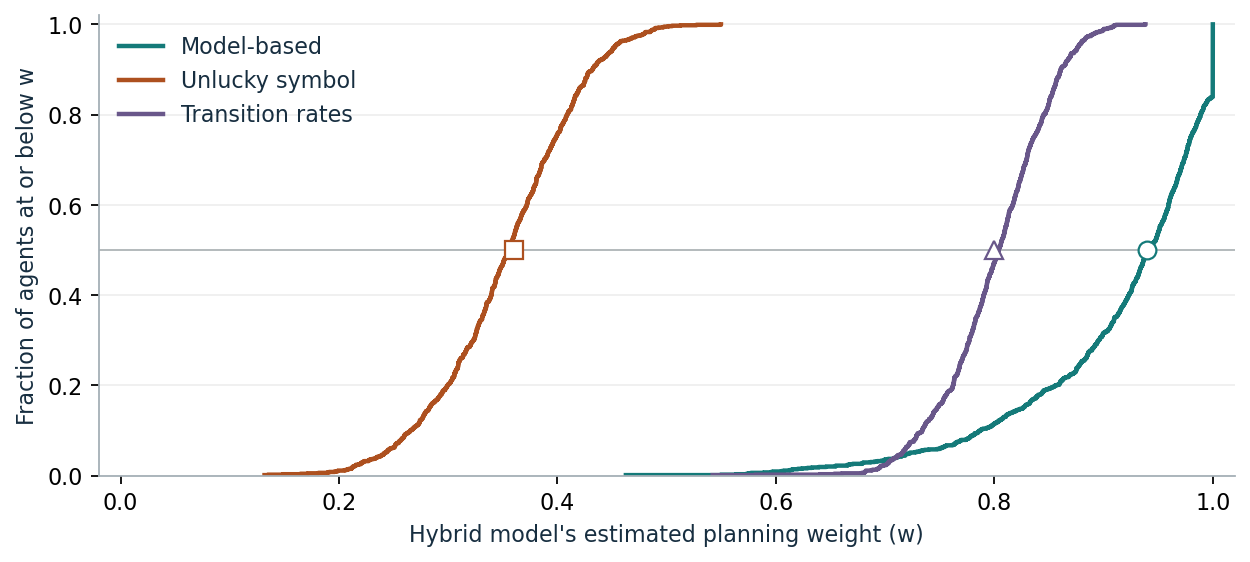

In [6]:
paper_test = a.fixed_weight_table(agents)
paper_test['published_2.5%'] = pd.Series({'MB': .74, 'Unlucky': .24, 'TDLR': .70})
paper_test['published_97.5%'] = pd.Series({'MB': 1., 'Unlucky': .48, 'TDLR': .90})
result_table(paper_test.reset_index(), "figure2_weight_comparison.csv")
display(Markdown(f"The correct planner's lower 2.5th percentile is **{paper_test.loc['MB','replicate_2.5%']:.2f}**, "
                 "compared with **0.74** in the paper. Agreement is closer at the medians than in this tail."))
figure(plots.weight_plot(agents), "figure2_weights.png")

**Recovery extension at a human task length.** The paper varied the generating rule while holding each generator’s parameters fixed. Here we also vary the parameters. For each family, independently draw the parameters below for 100 new agents, simulate 250 trials per agent with one first-stage configuration, and fit all five families. Each dataset gets an independent seed. Recovery depends on these generating ranges. In particular, TDLR agents in this exercise always learn faster after common transitions, and unlucky agents discount first action 0.

Parameter recovery compares known and fitted values using the generating family, even when another family wins BIC. Bias is mean estimated minus true value. RMSE retains parameter units. Spearman’s correlation measures whether the fit ranks individuals correctly. The diagonal in each panel marks exact recovery. The full results table includes every free parameter of every family.

,draw low,draw high
alpha1,0.15,0.85
alpha2,0.15,0.85
lam,0.15,0.85
beta1,2.00,8.00
beta2,2.00,8.00
w,0.10,0.90
p,-0.25,0.25
eta,0.25,0.80
alpha_common,0.55,0.90
alpha_rare,0.10,0.45


,generator,parameter,n,spearman_r,bias,rmse,at_bound
10,Hybrid,alpha1,100,0.621,-0.034,0.212,0.07
11,Hybrid,alpha2,100,0.951,0.014,0.065,0.00
12,Hybrid,lam,100,0.528,0.063,0.289,0.28
13,Hybrid,beta1,100,0.800,0.556,2.026,0.01
14,Hybrid,beta2,100,0.918,0.219,1.471,0.00
15,Hybrid,w,100,0.787,-0.039,0.159,0.06
16,Hybrid,p,100,0.939,-0.011,0.055,0.00


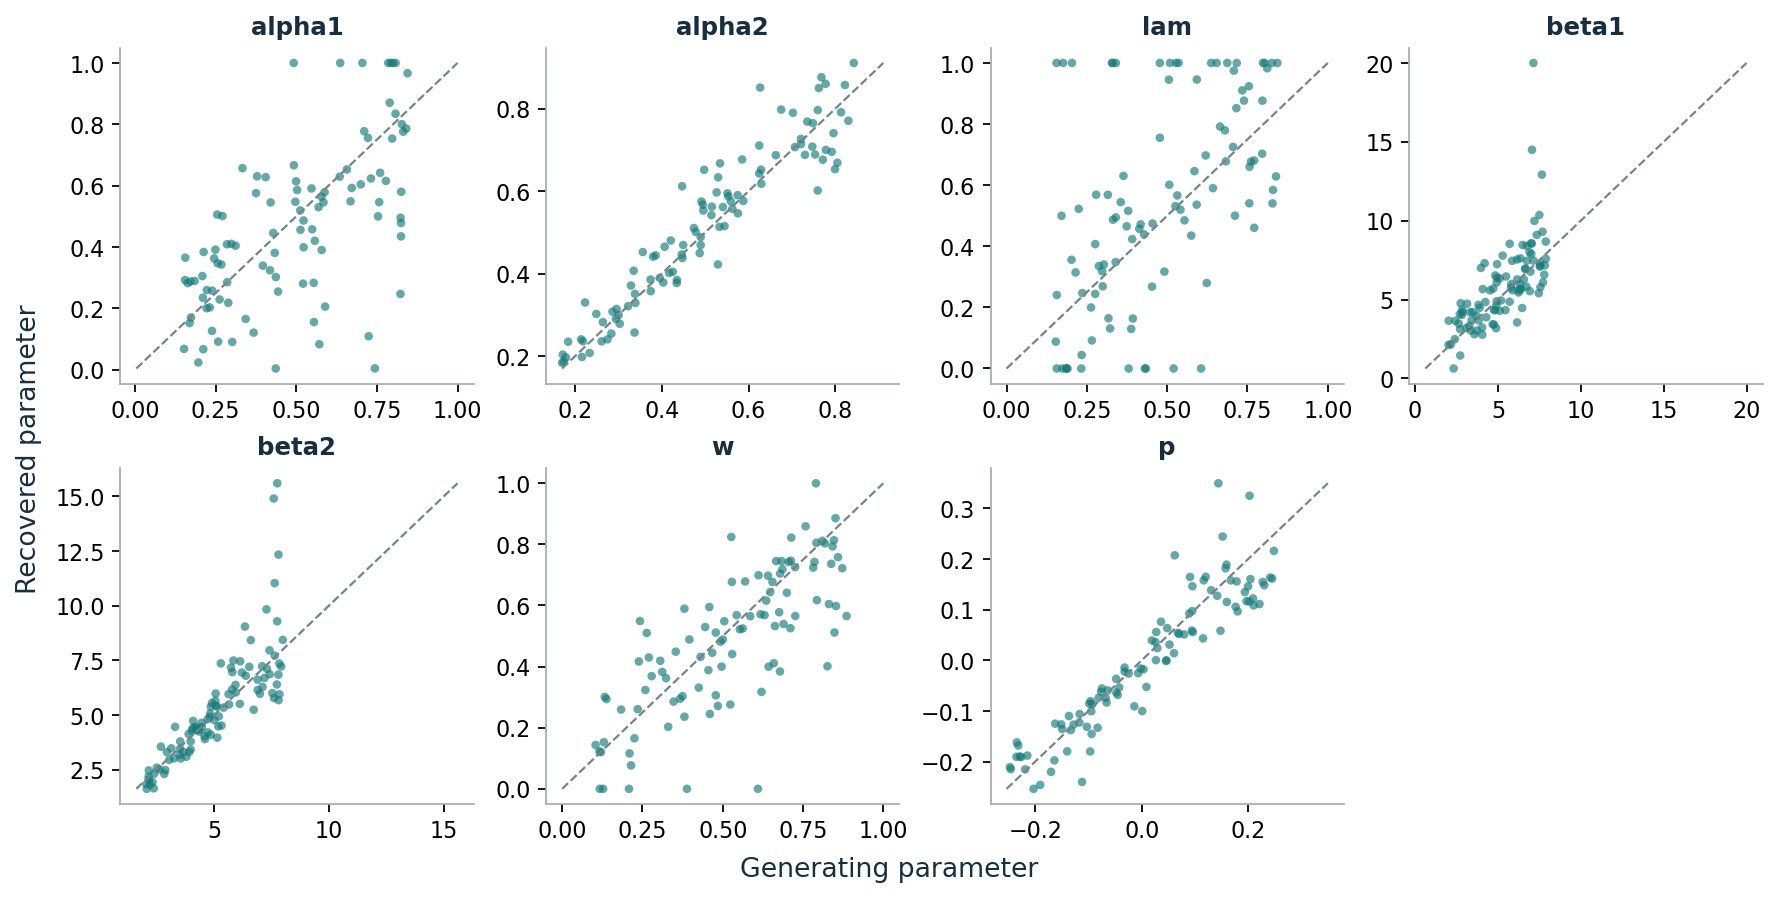

In [7]:
display(pd.DataFrame(a.GENERATING_RANGES, index=["draw low", "draw high"]).T)
recovery, = run_stage("recovery", settings=settings["recovery"], jobs=JOBS, refresh=REFIT)
metrics = a.parameter_recovery(recovery)
metrics.to_csv(OUT/"parameter_recovery.csv", index=False)
display(metrics.loc[metrics.generator.eq("Hybrid")].round(3))
figure(plots.parameter_plot(recovery), "parameter_recovery.png")

**Model recovery.** Rows give the known generating family. Columns give the family with the lowest BIC on that agent’s data. The diagonal counts correct selections. Off-diagonal cells quantify which strategies the comparison confuses at this trial length. Here the fitter can choose among all five families.

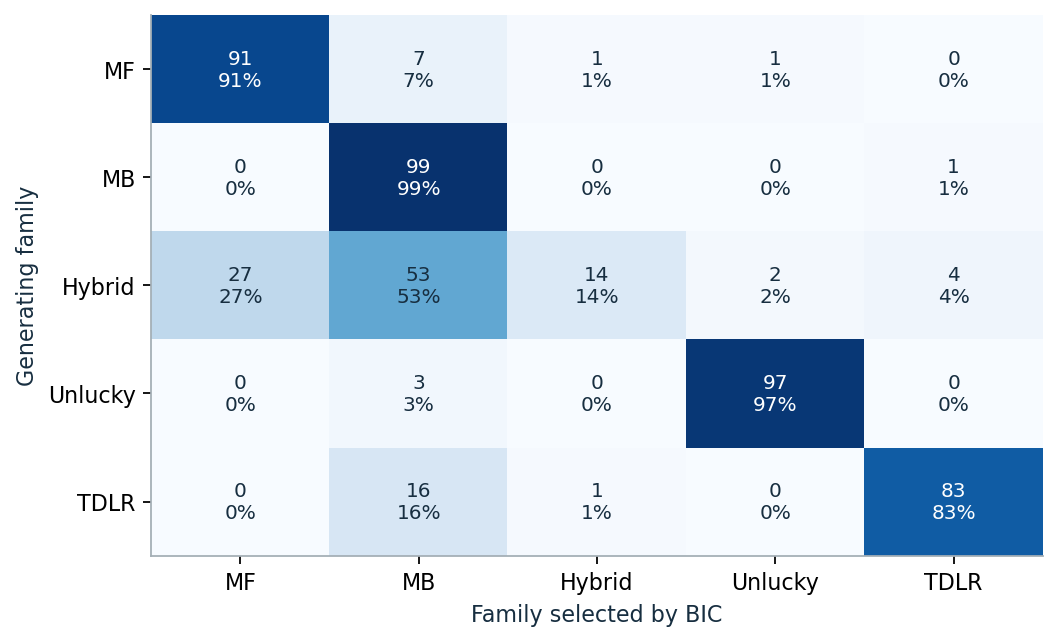

For hybrid agents, fitted and true planning weights have Spearman **0.79** and RMSE **0.16**. BIC selects the generating hybrid in **14/100** cases and selects pure MB in **53**. Parameter recovery assumes the family is already known. Model recovery tests that assumption.

In [8]:
confusion = a.model_recovery(recovery)
confusion.to_csv(OUT/"model_recovery_counts.csv")
figure(plots.confusion_plot(confusion), "model_recovery.png")
hybrid_selections = confusion.loc["Hybrid"]
w_metrics = metrics.query("generator == 'Hybrid' and parameter == 'w'").iloc[0]
display(Markdown(f"For hybrid agents, fitted and true planning weights have Spearman "
                 f"**{w_metrics.spearman_r:.2f}** and RMSE **{w_metrics.rmse:.2f}**. "
                 f"BIC selects the generating hybrid in **{hybrid_selections['Hybrid']}/{hybrid_selections.sum()}** "
                 f"cases and selects pure MB in **{hybrid_selections['MB']}**. "
                 "Parameter recovery assumes the family is already known. Model recovery tests that assumption."))

## 4 · Fit and compare models on the published choices

Each participant gets their own parameters. The likelihood scores **both** choices in each completed trial, conditional on prior outcomes, the first-stage configuration, and the reached second state. We estimate bounded maximum likelihood by L-BFGS-B with analytic gradients, optimizing inverse temperatures in log coordinates. We use ten starts and also initialize the more flexible models at their nested solutions. BIC and AIC use the unpenalized choice likelihood.

For $T$ completed trials and $k$ free parameters we use $n=2T$ scored choices and $\mathrm{BIC}=2\,\mathrm{NLL}+k\log n$. Summing individual BICs asks which *one family* best describes a cohort allowing each participant different parameters. *Individual wins* counts participants whose own BIC favors that family. We also compute $\mathrm{AIC}=2\,\mathrm{NLL}+2k$ to test sensitivity to the complexity penalty. Delta scores measure distance above the best within a cohort. Exact ties resolve by fewer parameters and then model name. Model overlap, boundary fits, and finite trial counts limit how literally either criterion can identify an individual’s strategy.

In [9]:
fits, = run_stage("human", settings=settings["human"], jobs=JOBS, refresh=REFIT)
assert len(fits) == audit.participants.sum()*len(a.FAMILIES) and np.isfinite(fits.bic).all()
comparison = a.model_comparison(fits)
result_table(comparison, "model_comparison.csv")
convergence = fits.groupby("model").agg(fits=("model","size"), best_start_converged=("success","sum"),
                                         fewest_converged_starts=("n_converged","min"))
display(convergence)
# Cross-check any best solution that issued a line-search warning at a boundary.
for row in fits.loc[~fits.success].itertuples(index=False):
    subset = complete[complete.cohort.eq(row.cohort) & complete.participant.eq(row.participant)]
    observed = subset[a.OBS].to_numpy(dtype=np.int64)
    free = PARAMS[row.model]
    start = [getattr(row, name) for name in free]
    retry = minimize(lambda t: nll(row.model, t, observed), start, bounds=[BOUNDS[n] for n in free],
                     method='SLSQP', options={'maxiter': 500, 'ftol': 1e-11})
    print(f'{row.model}, {row.participant}: independent optimizer converged={retry.success}, '
          f'absolute NLL difference={abs(retry.fun-row.nll):.2g}. Participant retained.')
    assert retry.success and abs(retry.fun-row.nll) < 1e-4
winners = comparison.drop_duplicates("cohort").set_index("cohort").model
aic_winners = comparison.sort_values("aic").drop_duplicates("cohort").set_index("cohort").model

,cohort,model,bic,aic,individual_wins,delta_bic,delta_aic
0,Common instructions,MB,58707.496,55846.217,130,0.000,280.178
1,Common instructions,TDLR,59142.637,55566.039,30,435.141,0.000
2,Common instructions,Unlucky,59487.379,55910.781,15,779.883,344.742
3,Common instructions,MF,60180.641,55888.723,28,1473.145,322.684
4,Common instructions,Hybrid,60635.995,55628.757,3,1928.499,62.718
5,Magic carpet,MB,10391.938,10008.279,17,0.000,95.572
6,Magic carpet,Unlucky,10449.215,9969.640,2,57.277,56.934
7,Magic carpet,TDLR,10475.840,9996.266,2,83.902,83.559
8,Magic carpet,Hybrid,10584.111,9912.707,2,192.173,0.000
9,Magic carpet,MF,11190.029,10614.540,1,798.091,701.833


,fits,best_start_converged,fewest_converged_starts
model,,,
Hybrid,251,251,9
MB,251,251,8
MF,251,251,10
TDLR,251,250,7
Unlucky,251,251,10


TDLR, subject_121: independent optimizer converged=True, absolute NLL difference=6.5e-07. Participant retained.


The paper also compares the hybrid’s planning weight across human cohorts. The mean and median below summarize individual fits. The interval bootstraps participants within a cohort. The last two columns count estimates at the lower and upper bound, where small data changes can materially change the estimate. [Published Figure 4](https://www.nature.com/articles/s41562-020-0905-y/figures/4)

In [10]:
weight_rows = []
for i, cohort in enumerate(a.COHORTS):
    w = fits.loc[fits.cohort.eq(cohort) & fits.model.eq("Hybrid"), "w"].to_numpy()
    mean, low, high = a.bootstrap_means(w, SEED+20+i)
    weight_rows.append(dict(cohort=cohort, n=len(w), mean=mean[0], mean_ci_low=low[0],
                            mean_ci_high=high[0], median=np.median(w),
                            at_zero=np.isclose(w, 0, atol=1e-6).sum(),
                            at_one=np.isclose(w, 1, atol=1e-6).sum()))
weights = pd.DataFrame(weight_rows).set_index("cohort")
result_table(weights.reset_index(), "human_hybrid_weights.csv")

,cohort,n,mean,mean_ci_low,mean_ci_high,median,at_zero,at_one
0,Common instructions,206,0.343,0.295,0.390,0.248,76,6
1,Spaceship,21,0.630,0.489,0.766,0.691,1,1
2,Magic carpet,24,0.678,0.576,0.773,0.792,1,0


### Posterior predictive check of the BIC winner

For each participant, form a posterior from the BIC winner’s joint choice likelihood and independent uniform priors on the bounds below. A tempered particle pilot helps find posterior regions. Fresh importance samples, weighted by the exact likelihood, prior, and proposal density, approximate this posterior. The sampler checks effective sample size, maximum particle weight, and agreement between two subsamples.

For each replicated cohort we draw a new parameter vector for each person and play a fresh game. We reuse the observed first-stage announcements, reward-probability paths, and completed-trial positions. We generate both actions, the common or rare transition, and the reward. Each simulated learner updates from **its own simulated history**. This is a conditional check for the participants and environments studied.

Each of 500 replicated cohorts produces four participant-mean stay probabilities. Solid lines give observed means, dashed lines give average predictions, and shading gives central 95% posterior predictive intervals. These describe variation across replicated datasets conditional on these participants. The earlier bootstrap intervals describe variation from resampling participants. [Predictive algorithm](replication/predictive.py)

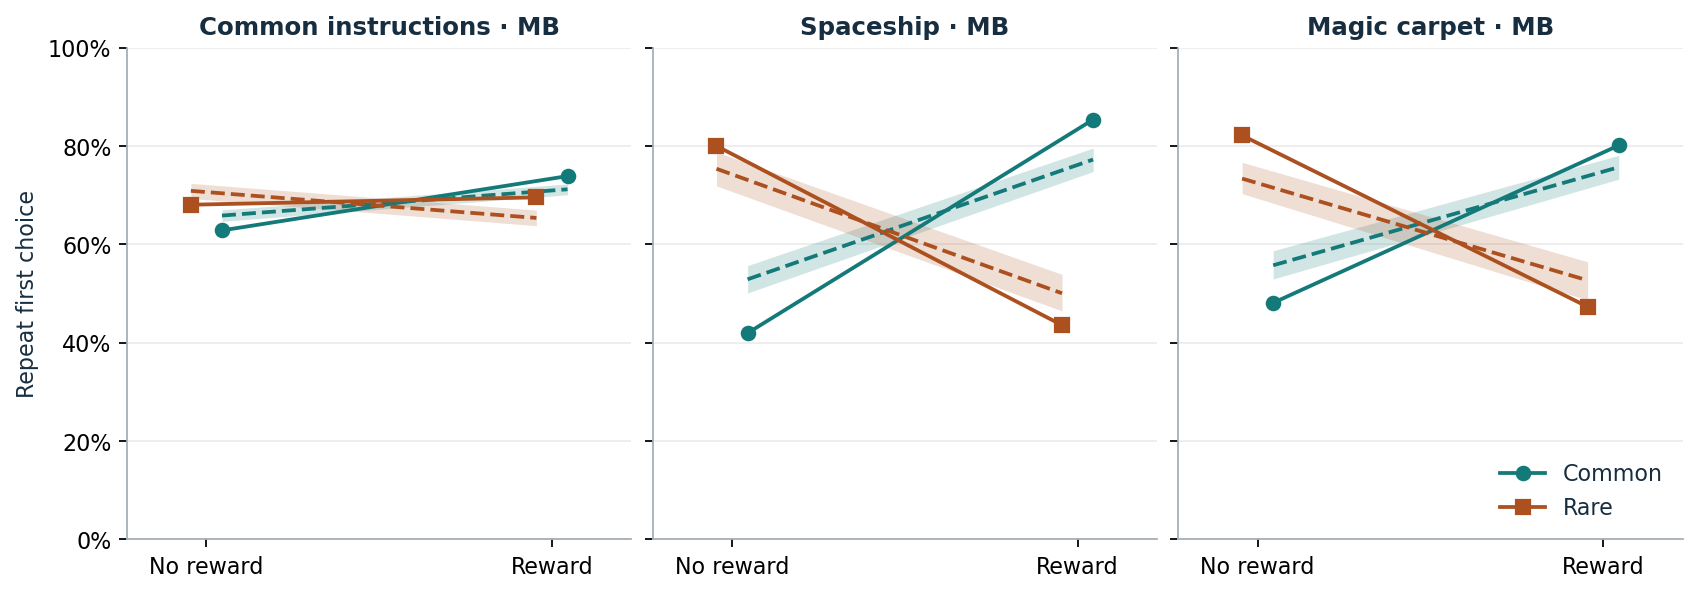

,cohort,model,reward,common,observed,pred_mean,lower,upper,error_pp,covered
0,Common instructions,MB,1,1,0.739,0.712,0.701,0.723,-2.679,False
1,Common instructions,MB,1,0,0.696,0.654,0.638,0.670,-4.188,False
2,Common instructions,MB,0,1,0.628,0.659,0.647,0.670,3.018,False
3,Common instructions,MB,0,0,0.681,0.709,0.693,0.724,2.824,False
4,Magic carpet,MB,1,1,0.801,0.757,0.732,0.781,-4.428,False
5,Magic carpet,MB,1,0,0.473,0.527,0.487,0.565,5.374,False
6,Magic carpet,MB,0,1,0.481,0.557,0.530,0.587,7.640,False
7,Magic carpet,MB,0,0,0.822,0.734,0.703,0.767,-8.779,False
8,Spaceship,MB,1,1,0.854,0.773,0.748,0.796,-8.121,False
9,Spaceship,MB,1,0,0.436,0.501,0.465,0.539,6.482,False


,participants,passed_sampler_checks,min_effective_samples,median_effective_samples
cohort,,,,
Common instructions,206,206,389.9,1229.2
Magic carpet,24,24,723.9,1544.3
Spaceship,21,21,1386.9,1601.3


In [11]:
cells, diagnostics = run_stage("predictive", settings=settings["predictive"], jobs=JOBS, refresh=REFIT)
cells = cells.assign(covered=cells.observed.between(cells.lower, cells.upper),
                     error_pp=100*(cells.pred_mean-cells.observed))
for cohort in a.COHORTS:
    empirical = human_stay.loc[human_stay.cohort.eq(cohort), list(a.CELL_NAMES)].mean().to_numpy()
    group = cells[cells.cohort.eq(cohort)].set_index(["reward","common"])
    assert np.allclose(empirical, group.reindex(a.CELLS)["observed"])
figure(plots.predictive_plot(cells), "posterior_predictive.png")
display(cells[["cohort","model","reward","common","observed","pred_mean","lower","upper","error_pp","covered"]].round(3))
display(diagnostics.groupby("cohort").agg(participants=("participant","count"),
        passed_sampler_checks=("posterior_ok","sum"), min_effective_samples=("ess","min"),
        median_effective_samples=("ess","median")).round(1))

## 5 · Replication verdict

The authors report an interaction about 5.9 times the common-instructions value in each story task. Their estimate comes from hierarchical logistic regression. Our ratio uses the mean of the individual logistic coefficients. The comparison below also shows the Figure 2 medians and the human hybrid estimates. [Full-text preprint, human results](https://www.biorxiv.org/content/10.1101/682922v3.full)

In [12]:
effects = contrasts.pivot(index="cohort", columns="effect", values="estimate")
ratio = effects.interaction_coef / effects.loc["Common instructions", "interaction_coef"]
medians = weights["median"]
story = list(a.COHORTS[1:])
stronger = (ratio[story] > 1).all()
higher_w = (medians[story] > medians["Common instructions"]).all()
fixed_medians = paper_test.reproduced_median
same_order = fixed_medians["MB"] > fixed_medians["TDLR"] > fixed_medians["Unlucky"]
checks = pd.DataFrame([
    {"comparison": "Fig. 2 median w (MB / Unlucky / TDLR)", "paper": "0.94 / 0.36 / 0.80",
     "this run": " / ".join(f"{v:.3f}" for v in fixed_medians), "agreement": "same order" if same_order else "differs"},
    {"comparison": "Interaction relative to common (Spaceship / Magic carpet)", "paper": "about 5.9× in both",
     "this run": f"{ratio['Spaceship']:.2f}× / {ratio['Magic carpet']:.2f}×", "agreement": "larger in both" if stronger else "mixed"},
    {"comparison": "Human median w (common / Spaceship / Magic carpet)", "paper": "higher in both story tasks",
     "this run": " / ".join(f"{medians[k]:.3f}" for k in a.COHORTS), "agreement": "higher in both" if higher_w else "mixed"},
])
display(checks)
verdict = "The main behavioral result reproduces" if higher_w and stronger and same_order else "The behavioral results show mixed agreement"
inside = int(cells.covered.sum())
largest = cells.iloc[cells.error_pp.abs().argmax()]
flagged = int((~diagnostics.posterior_ok).sum())
display(Markdown(
    f"**{verdict}.** The table shows the size of the instruction-group difference and how much apparent "
    f"model-free influence the hybrid fit assigns to each type of planner.\n\n"
    f"**Model comparison.** In common / Spaceship / Magic carpet order, BIC selects "
    f"**{' / '.join(winners[k] for k in a.COHORTS)}** and AIC selects "
    f"**{' / '.join(aic_winners[k] for k in a.COHORTS)}**. "
    f"At 250 trials, BIC's tendency to select a simpler family also appears in the model-recovery matrix.\n\n"
    f"**Absolute fit.** The winners' 95% intervals contain **{inside} of {len(cells)}** observed stay probabilities. "
    f"The largest discrepancy is **{abs(largest.error_pp):.1f} percentage points** in {largest.cohort} "
    f"after a {'reward' if largest.reward else 'nonreward'} and a {'common' if largest.common else 'rare'} transition "
    f"(observed {largest.observed:.1%}, predicted {largest.pred_mean:.1%}). "
    f"The sampler flagged {flagged} of {len(diagnostics)} participant posteriors. "
    "The pointwise intervals refer to related cells from the same participants."
))

,comparison,paper,this run,agreement
0,Fig. 2 median w (MB / Unlucky / TDLR),0.94 / 0.36 / 0.80,0.943 / 0.355 / 0.804,same order
1,Interaction relative to common (Spaceship / Ma...,about 5.9× in both,6.11× / 5.66×,larger in both
2,Human median w (common / Spaceship / Magic car...,higher in both story tasks,0.248 / 0.691 / 0.792,higher in both


**The main behavioral result reproduces.** The table shows the size of the instruction-group difference and how much apparent model-free influence the hybrid fit assigns to each type of planner.

**Model comparison.** In common / Spaceship / Magic carpet order, BIC selects **MB / MB / MB** and AIC selects **TDLR / Hybrid / Hybrid**. At 250 trials, BIC's tendency to select a simpler family also appears in the model-recovery matrix.

**Absolute fit.** The winners' 95% intervals contain **0 of 12** observed stay probabilities. The largest discrepancy is **10.9 percentage points** in Spaceship after a nonreward and a common transition (observed 42.0%, predicted 52.9%). The sampler flagged 0 of 251 participant posteriors. The pointwise intervals refer to related cells from the same participants.

### Why estimates can differ

- **Objective and bounds.** The published Stan parameterizations allow positive temperatures and unconstrained perseveration. Here temperatures range from 0.01 to 20, $p$ from −2 to 2, and rates, $\lambda,w,\eta$ from 0 to 1. A finite cap can affect highly consistent choosers. Public Figure 2 prior terms enter only the synthetic-agent fit. Human fits use individual maximum likelihood. The predictive check uses independent bounded participant posteriors. [Original hierarchical model](https://github.com/carolfs/muddled_models/blob/master/analyses_simulations/models/hybrid.stan)
- **Inference and comparison.** The paper estimates stay coefficients hierarchically and reports AIC and PSIS-LOO comparisons. We bootstrap participants, score both choices in five reinforcement-learning families, and use summed individual BIC. AIC on the same likelihood shows how the answer depends on the complexity penalty. Human Unlucky and TDLR fits and the five-way recovery matrix extend the authors’ comparisons.
- **Sample and random variation.** We retain all 251 people with released main-task choices and remove practice and response timeouts. The authors reported one unavailable common-instructions AIC fit in their model-comparison analysis. The three full human samples enter our BIC calculation. Independent random streams and different optimizers affect individual fits. [Trial audit](data/README.md) · [Authors’ analysis](https://github.com/carolfs/muddled_models)
- **Scope.** The human estimates reuse the published participants. The simulations show that mistaken planning can produce the reported signature. The particular beliefs of individual participants remain uncertain. This notebook targets the core choice results in Figures 2 and 4. The paper’s questionnaire and screen-position analyses address additional questions.